# 糖尿病数据集（Diabetes Dataset）

## 概述

- **what**：sklearn 内置的经典**回归**数据集，442 个糖尿病患者的 10 项生理特征，目标是 1 年后疾病进展的量化评分（25~346，连续值）
- **why**：目标值连续 → 天然适合**线性回归**（iris 是分类任务，两者正好互补）
- **how**：`load_diabetes()` 一行加载，数据内置在 sklearn 包里，无需联网

特征说明：age 年龄 / sex 性别（二值编码）/ bmi 体重指数 / bp 平均血压 / s1~s6 六项血清化验指标（tc 总胆固醇、ldl 低密度脂蛋白、hdl 高密度脂蛋白、tch 总胆固醇÷HDL、ltg log 甘油三酯、glu 血糖）

## 数据准备

In [1]:
import pandas as pd  # 表格数据处理
import numpy as np  # 数值计算
import matplotlib.pyplot as plt  # 基础绘图库
import seaborn as sns  # 基于 matplotlib 的统计可视化库
from sklearn.datasets import load_diabetes  # 加载 sklearn 自带的糖尿|病回归数据集

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 按顺序取第一个系统里存在的字体
plt.rcParams['axes.unicode_minus'] = False  # 修复负号显示为方块的问题
sns.set_theme(style='whitegrid')  # 统一 seaborn 图表风格

## 1. 获取数据

In [2]:
diabetes = load_diabetes()  # 返回 Bunch 对象（类似字典）：data / target / feature_names / DESCR 等，本地加载无需联网
data = pd.DataFrame(data=diabetes.data, columns=diabetes.feature_names)  # 特征数组转 DataFrame，列名用 sklearn 提供的特征名
data['target'] = diabetes.target  # 新增 target 列：一年后疾病进展的量化评分（连续值 → 回归任务）
data.head()  # 预览前 5 行，确认数据形状与列名

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. 统计分析数据

In [3]:
data.info()  # 行列数、各列类型与非空计数：442 行 × 11 列，全部 float64 且无缺失
data.describe().round(3)  # 特征统计：均值≈0（已中心化），取值范围约 [-0.13, 0.2]（sklearn 已按列归一化）
data['target'].describe().round(2)  # 目标值统计：25~346，均值≈152，是连续数值 → 适合线性回归

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


count    442.00
mean     152.13
std       77.09
min       25.00
25%       87.00
50%      140.50
75%      211.50
max      346.00
Name: target, dtype: float64

## 3. 可视化分析数据

### 3.1 单变量分析：直方图 —— 了解每列的分布形态

C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\2585427188.py:8: UserWarning: Glyph 21333 (\N{CJK UNIFIED IDEOGRAPH-5355}) missing from font(s) Arial.
  plt.tight_layout()  # 自动排版，防止标题重叠
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\2585427188.py:8: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) Arial.
  plt.tight_layout()  # 自动排版，防止标题重叠
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\2585427188.py:8: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) Arial.
  plt.tight_layout()  # 自动排版，防止标题重叠
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\2585427188.py:8: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  plt.tight_layout()  # 自动排版，防止标题重叠
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\2585427188.py:8: UserWarning: Glyph 26512 (\N{CJK UNIFIED IDEOGRAPH-6790}) missing from font(s) Arial.
  plt.tight_layout()  # 自动排版，防止标题重叠
C:\Users\Admini

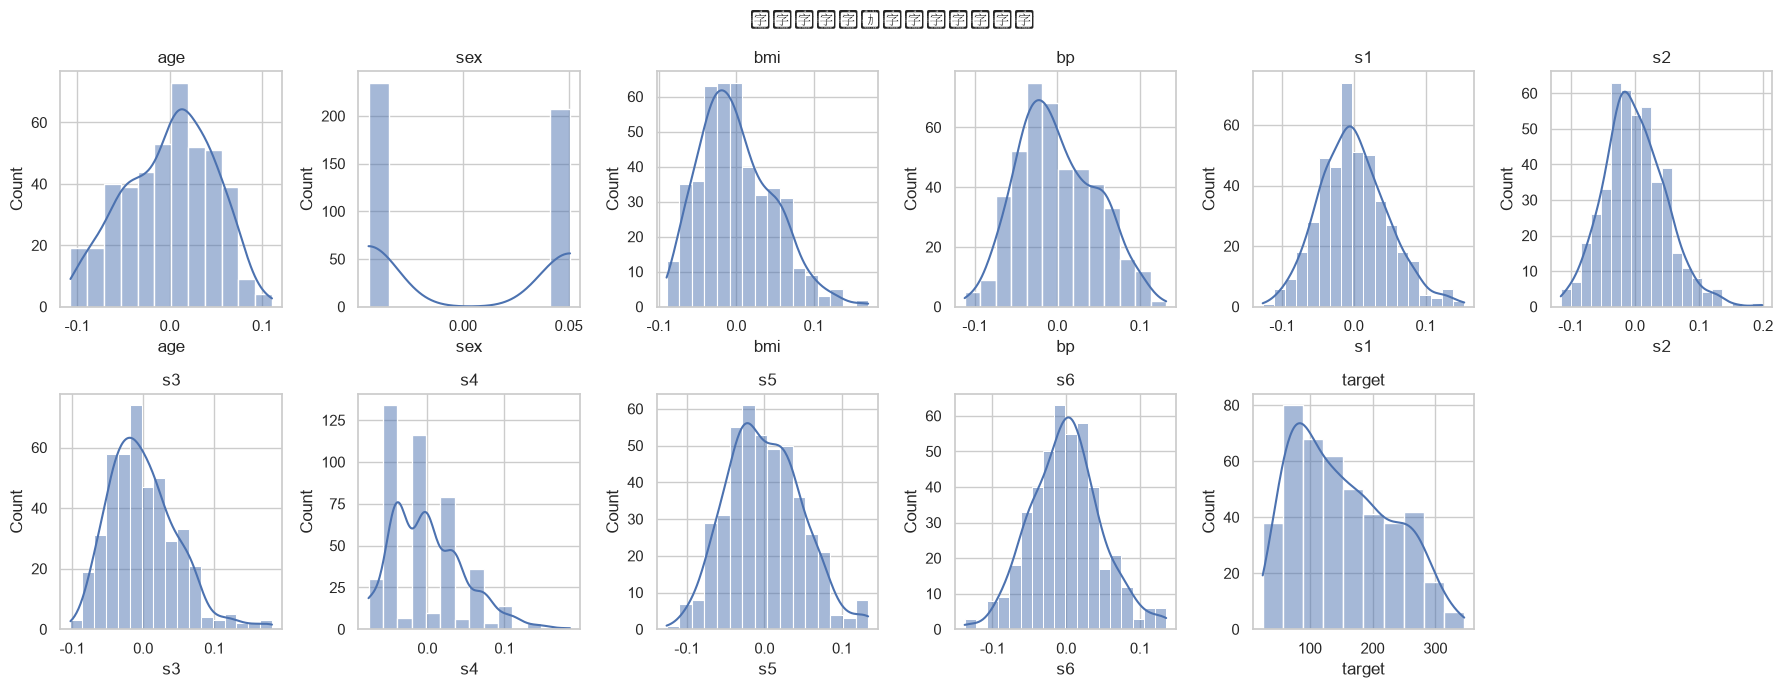

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(18, 7))  # 2 行 6 列共 12 个子图：10 个特征 + 1 个目标值
fig.suptitle('单变量分析：各列分布直方图', fontsize=14)  # 总标题
for i, col in enumerate(data.columns):  # 逐列绘制分布
    ax = axes[i // 6, i % 6]  # 按序号定位子图的行列位置
    sns.histplot(data[col], kde=True, ax=ax)  # 直方图 + 核密度曲线，观察分布形态
    ax.set_title(col)  # 子图标题为列名
axes[1, 5].axis('off')  # 隐藏多余的最后一个空白子图
plt.tight_layout()  # 自动排版，防止标题重叠
plt.show()  # 渲染图表

### 3.2 双变量分析：热力图 —— 特征之间、特征与目标的相关性

C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1715273774.py:5: UserWarning: Glyph 21452 (\N{CJK UNIFIED IDEOGRAPH-53CC}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1715273774.py:5: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1715273774.py:5: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1715273774.py:5: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1715273774.py:5: UserWarning: Glyph 26512 (\N{CJK UNIFIED IDEOGRAPH-6790}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\17

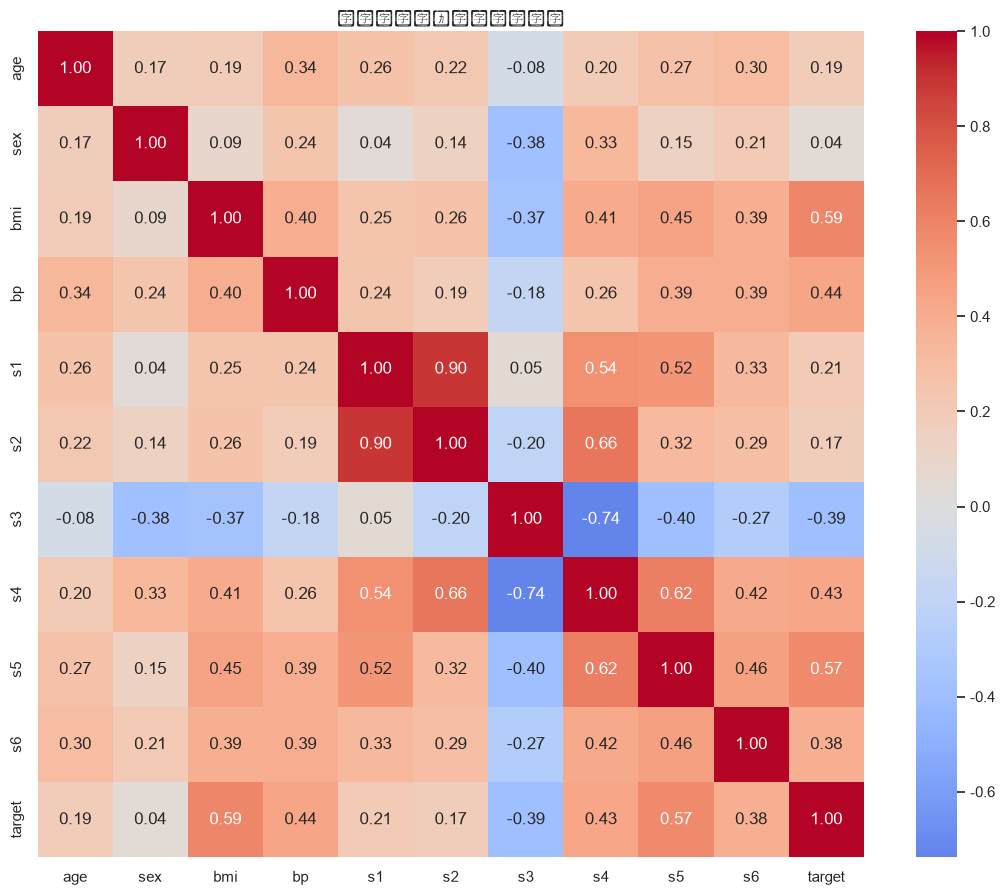

In [5]:
corr = data.corr()  # 皮尔逊相关系数矩阵：取值 [-1, 1]，绝对值越大线性关系越强
plt.figure(figsize=(11, 9))  # 画布尺寸，保证 11×11 数值标注不拥挤
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)  # 热力图：红=正相关，蓝=负相关
plt.title('双变量分析：相关性热力图')  # 标题
plt.tight_layout()  # 排版
plt.show()  # 渲染

### 3.3 双变量分析：散点图 + 回归线 —— 挑出与目标最相关的特征

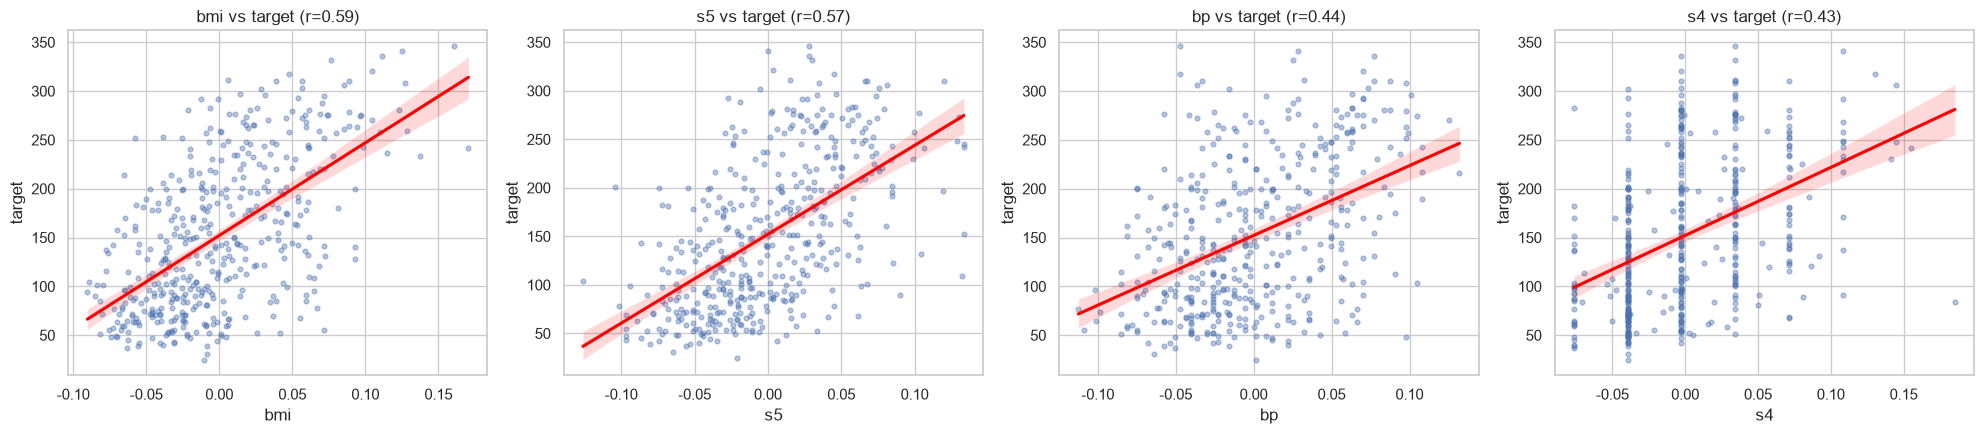

In [6]:
top_feats = ['bmi', 's5', 'bp', 's4']  # 从热力图最后一行挑出与 target 线性相关性最强的 4 个特征
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))  # 一行四列子图
for ax, col in zip(axes, top_feats):  # 每个特征一个子图
    r = corr.loc[col, 'target']  # 取该列与 target 的相关系数
    sns.regplot(x=col, y='target', data=data, ax=ax,
                scatter_kws={'s': 12, 'alpha': 0.4}, line_kws={'color': 'red'})  # 散点 + 红色最小二乘回归线，直观展示线性趋势
    ax.set_title(f'{col} vs target (r={r:.2f})')  # 标题带上相关系数
plt.tight_layout()  # 排版
plt.show()  # 渲染

### 3.4 特征箱线图 —— 量纲与离群点检查

C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1429938615.py:4: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1429938615.py:4: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1429938615.py:4: UserWarning: Glyph 31665 (\N{CJK UNIFIED IDEOGRAPH-7BB1}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1429938615.py:4: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\1429938615.py:4: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) Arial.
  plt.tight_layout()  # 排版
C:\Users\Administrator\AppData\Local\Temp\ipykernel_88248\14

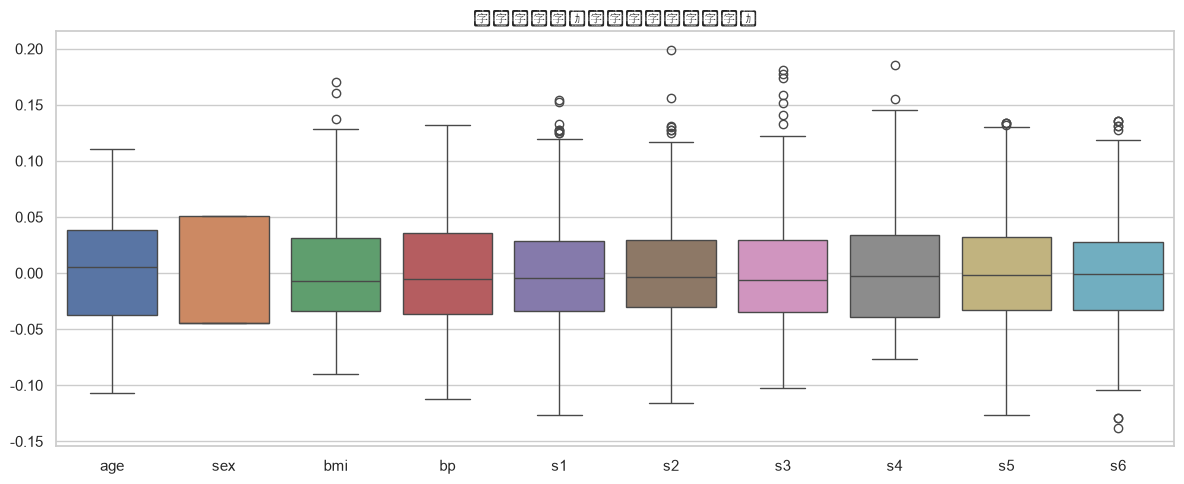

In [7]:
plt.figure(figsize=(12, 5))  # 画布尺寸
sns.boxplot(data=data.drop(columns='target'))  # 10 个特征的箱线图：箱体为四分位距，圆圈为统计学离群点
plt.title('特征箱线图（量纲与离群点检查）')  # 特征已归一化、量纲一致；sex 只有两个取值所以箱体退化为一条线
plt.tight_layout()  # 排版
plt.show()  # 渲染

### 3.5 多变量分析：3D 散点图 —— 两个最相关特征与目标的关系

d:\anaconda3\envs\torchLearnEnv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22810 (\N{CJK UNIFIED IDEOGRAPH-591A}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\torchLearnEnv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\torchLearnEnv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\torchLearnEnv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26512 (\N{CJK UNIFIED IDEOGRAPH-6790}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\torchLearnEnv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) Arial.
  f

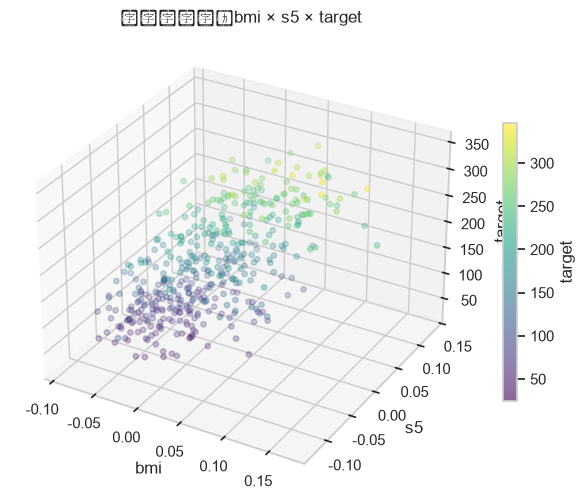

In [8]:
fig = plt.figure(figsize=(8, 6))  # 画布
ax = fig.add_subplot(111, projection='3d')  # 添加 3D 坐标系
sc = ax.scatter(data['bmi'], data['s5'], data['target'],
                c=data['target'], cmap='viridis', s=15, alpha=0.6)  # bmi/s5 两个最相关特征与 target 的 3D 散点，颜色映射目标高低
ax.set_xlabel('bmi')  # x 轴：体重指数
ax.set_ylabel('s5')  # y 轴：血清第 5 项（log 甘油三酯）
ax.set_zlabel('target')  # z 轴：疾病进展评分
fig.colorbar(sc, ax=ax, shrink=0.6, label='target')  # 颜色条辅助读图
plt.title('多变量分析：bmi × s5 × target')  # 标题
plt.show()  # 渲染

## 4. 数据清洗（逐项检查）

In [9]:
print('缺失值总数:', data.isna().sum().sum())  # 全表缺失值计数 → 0，无缺失
print('完全重复行数:', data.duplicated().sum())  # 重复行计数 → 0，无重复
print('target 取值范围: [%d, %d]' % (data['target'].min(), data['target'].max()))  # 25~346，均为合理生理评分，无异常录入
q1, q3 = data['bmi'].quantile([0.25, 0.75])  # 以 bmi 为例：取上下四分位数
iqr = q3 - q1  # 四分位距
outliers = data[(data['bmi'] < q1 - 1.5 * iqr) | (data['bmi'] > q3 + 1.5 * iqr)]  # IQR 法筛出离群行
print('bmi 的 IQR 离群点数量:', len(outliers))  # 即使检出少量离群点，也属于真实测量值而非录入错误

缺失值总数: 0
完全重复行数: 0
target 取值范围: [25, 346]
bmi 的 IQR 离群点数量: 3


### 检查结论：无需清洗

- diabetes 是 sklearn 内置的教学级数据集：**无缺失、无重复、无异常录入**
- 箱线图 / IQR 检出的少量统计离群点是**真实测量值**，应当保留
- 因此跳过清洗步骤，直接进入拆分与标准化（iris 那套 dropna / drop_duplicates / 范围过滤在这里没有实际作用）

## 5 & 6. 特征处理与数据拆分（先拆分，再标准化）

> 特征虽已被 sklearn 中心化并按列归一化，但各列标准差不同；StandardScaler 后每列标准差统一为 1，
> 对线性回归（尤其是带正则化的岭回归/Lasso）能让系数公平比较。

In [10]:
from sklearn.model_selection import train_test_split  # 数据集拆分工具
from sklearn.preprocessing import StandardScaler  # 标准化转换器

X = data[diabetes.feature_names]  # 特征矩阵：10 列
y = data['target']  # 目标值：连续的疾病进展评分

# 注意：fit() 只能作用在训练集上；测试集用训练集 fit 好的转换器去 transform，
# 否则测试集信息会泄露到训练过程，评估结果不可信
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=22)  # 80% 训练 / 20% 测试；固定 random_state 保证可复现

scaler = StandardScaler()  # 标准化：每列变为均值 0、标准差 1
x_train_s = pd.DataFrame(scaler.fit_transform(x_train), columns=X.columns, index=x_train.index)  # 训练集 fit_transform：学习均值方差并变换
x_test_s = pd.DataFrame(scaler.transform(x_test), columns=X.columns, index=x_test.index)  # 测试集只 transform：沿用训练集的规则

print('训练集:', x_train_s.shape, ' 测试集:', x_test_s.shape)  # 预期 (353, 10) / (89, 10)
print('训练集各列均值最大绝对值(应≈0):', x_train_s.mean().abs().max().round(6))  # 验证标准化生效
print('训练集各列标准差最小值(应≈1):', x_train_s.std().round(6).min())  # 验证标准化生效（sex 是二值列，标准差略小于 1 属正常）

训练集: (353, 10)  测试集: (89, 10)
训练集各列均值最大绝对值(应≈0): 0.0
训练集各列标准差最小值(应≈1): 1.001419


## 总结与参考

- **流程**：获取数据 → 统计分析 → 可视化（直方图 / 热力图 / 散点图 / 箱线图 / 3D 散点）→ 清洗检查（无需清洗）→ 先拆分再标准化
- **关键结论**：bmi、s5、bp 与目标值线性相关性最强，是线性回归的重点特征
- **复用**：其他 notebook 中 `from diabetes_utils import load_diabetes_ready` 即可一键得到训练/测试集
- 参考：scikit-learn 官方文档 [Diabetes dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset)